In this section, let us preprocess our dataset in the light of what we pinpointed in the exploratory data analysis part, and try our first baseline models.

In [1]:
import sys
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [2]:
sys.path.insert(0, str(Path.cwd().parent))

from src.data_loader import load_data

df_train, df_test = load_data()

In [3]:
from src.preprocessing import prepare_data, build_preprocessor

X_train, y_train = prepare_data(df_train)

preprocessor = build_preprocessor(X_train)

logistic_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

We avoid preprocessing our whole training set, as in the near future, we are going to perform cross validation. Scaling our training set right now would thus lead to data leakage.

In [4]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

logistic_pipeline.fit(X_fit, y_fit)

y_pred = logistic_pipeline.predict(X_val)

print("Baseline accuracy:", accuracy_score(y_val, y_pred))

Baseline accuracy: 0.7033057851239669


To avoid testing our baseline model on the final test set, we split again our training set into a "fit" test and a "validation" test. Without optimizing any hyperparameter, we reach a 70% baseline accuracy. From now on, every model we use must be higher than this accuracy.

70% is our accuracy score on the validation set. Let us see what is the accuracy score on the training set. If the training score is higher, this could imply overfitting.

In [5]:
y_fit_pred = logistic_pipeline.predict(X_fit)

print(f"The accuracy score on the training data set is {accuracy_score(y_fit, y_fit_pred)}")

The accuracy score on the training data set is 0.7061802397684994


There is no apparent overfitting: the accuracy on the training set is almost the same as on the test set. Either we underfit because of a too strict L2 penalization on the coefficients, either our model structurally underfits because the decision frontiers are not linear. Let us check whether non-linear models achieve a higher score.


In [6]:
clf = DecisionTreeClassifier(criterion='gini', max_depth=None)

clf.fit(X_fit, y_fit)

y_fit_pred = clf.predict(X_fit)
y_fit_acc = accuracy_score(y_fit, y_fit_pred)

y_val_pred = clf.predict(X_val)
y_val_acc = accuracy_score(y_val, y_val_pred)

print(f"The accuracy score on the train set is {y_fit_acc}")
print(f"The accuracy score on the test set is {y_val_acc}")


The accuracy score on the train set is 1.0
The accuracy score on the test set is 0.7694214876033058


The decision tree achieves 100% accuracy on the training set, suggesting that it has fitted the training data perfectly, potentially including noise and sample-specific patterns that do not reflect the underlying relationship between the features and the target variable.

Despite this substantial overfitting, the decision tree achieves a validation accuracy of 76.94%, approximately 6.6 percentage points higher than our logistic regression baseline.

This improvement suggests that the relationship between the features and the target may involve non-linearities or interactions that our baseline logistic regression cannot adequately capture.

We will therefore investigate more flexible models, starting by controlling the complexity of our decision tree, before exploring ensemble methods such as Random Forests.

To identify the optimal hyperparameters for our Decision Tree while limiting selection biais from repeatedly evaluating models on the test set, we perform a 5-fold cross-validation to evaluate model performance on unseen validation folds.

In [7]:
tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(criterion='gini', random_state=42))
])

param_grid = {"model__max_depth": [1, 2, 5, 10, 15, 20, 25, 30, 40]}

grid_search = GridSearchCV(
    tree_pipeline,
    param_grid,
    scoring="accuracy",
    cv=5,
    return_train_score=True    
)

grid_search.fit(X_train, y_train)

print(f"The optimal maximum depth is {grid_search.best_params_['model__max_depth']}, with a mean cross-validation accuracy of {grid_search.best_score_}")



The optimal maximum depth is 15, with a mean cross-validation accuracy of 0.7751322348214378


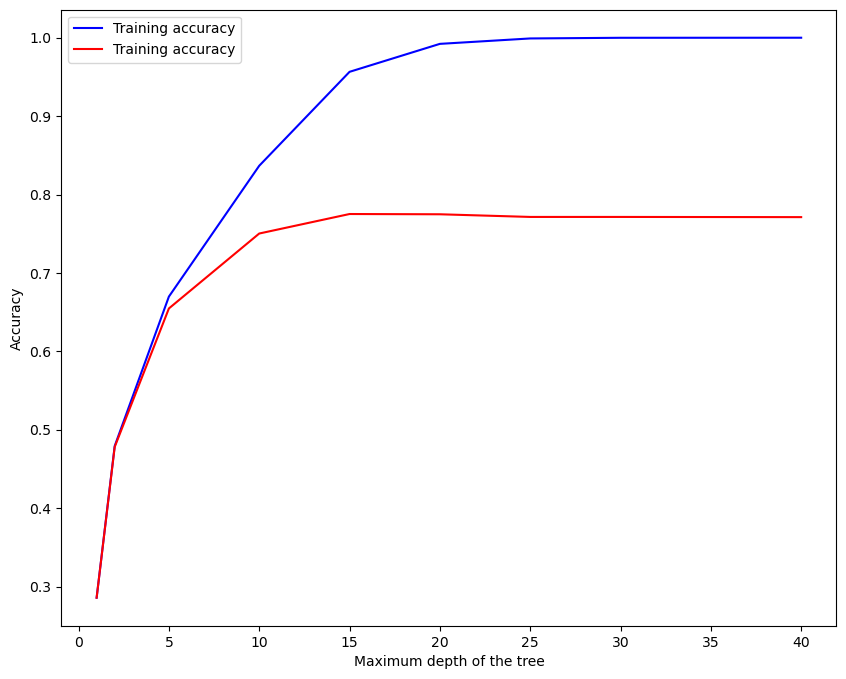

In [8]:
param = param_grid["model__max_depth"]

grid = pd.Series(grid_search.cv_results_)

train_accuracy = grid["mean_train_score"]
test_accuracy = grid["mean_test_score"] 

fig, ax = plt.subplots(figsize=(10,8))

ax.plot(
    param, train_accuracy, 
    color="blue", label="Training accuracy"
    )

ax.plot(
    param, test_accuracy, 
    color="red", label="Training accuracy"
    )

plt.xlabel("Maximum depth of the tree")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Among the maximum tree depths evaluated, a depth of 15 achieves the highest mean cross-validation accuracy, approximately 77.5%.

The curves show that validation accuracy initially increases with tree depth, before slightly decreasing and eventually stabilizing. Meanwhile, training accuracy continues to increase until it reaches 100%, suggesting that the tree becomes sufficiently flexible to memorize the training observations, potentially including noise.

Beyond a maximum depth of approximately 25, both training and validation accuracies plateau. This suggests that allowing additional depth no longer meaningfully changes the model's predictions, potentially because the trees have already reached their natural stopping conditions (leaf node impurity of 0).

These results illustrate the trade-off between model complexity and generalization: increasing tree depth improves the fit to the training data, but does not necessarily improve performance on unseen observations, or can even decrease it.

In [9]:
X_test, y_test = prepare_data(df_test)

y_test_pred = grid_search.best_estimator_.predict(X_test)

print(f"On the test set, the accuracy score reaches {accuracy_score(y_test, y_test_pred)}")

On the test set, the accuracy score reaches 0.781084656084656


Trees are faced with the biais-variance tradeoff : the more flexible our model, the lower the biais, but the higher the variance, as our model becomes more sensitive to the particularities of the training sample.

Random Forests combine multiple decision trees trained on bootstrap samples. At each node, a random subset of candidate features is selected, and the algorithm determines the best split among them based on impurity reduction. This introduces diversity between trees, helping reduce the variance of their aggregated predictions while retaining the flexibility of deep decision trees.

On a plain RandomForest model, let us check whether our validation accuracy improves.

In [10]:
rf = RandomForestClassifier(
    n_estimators=100, 
    criterion="gini")

rf.fit(X_fit, y_fit)

y_fit_pred = rf.predict(X_fit)
y_val_pred = rf.predict(X_val)

train_accuracy = accuracy_score(y_fit, y_fit_pred)
val_accuracy = accuracy_score(y_val, y_val_pred)

print(f"The accuracy on the train set is {train_accuracy}.")  
print(f"The accuracy on the validation set is {val_accuracy}.")

The accuracy on the train set is 1.0.
The accuracy on the validation set is 0.8607438016528925.
